# **Visualizing a ML Algorithm**

## **Data Collection & Exploration**

**Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving advertising.csv to advertising.csv


In [ ]:
data = pd.read_csv('advertising.csv')
data.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [ ]:
print(data.columns)

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')


In [ ]:
data.isna().sum()    # Checking for null values if any

,0
TV,0
Radio,0
Newspaper,0
Sales,0


In [ ]:
data.duplicated().sum()   # Checking for duplicate rows if any

np.int64(0)

In [ ]:
data.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [ ]:
print(f'Minimum Sales from Advertisements: {data['Sales'].min()}')
print(f'Maximum Sales from Advertisements: {data['Sales'].max()}')

Minimum Sales from Advertisements: 1.6
Maximum Sales from Advertisements: 27.0


For **Sales** these numbers are **units** like:

**1.6 ---> 1,600 units**  
**27.0 ---> 27,000 units**

In [ ]:
print(f'Minimum Money spent on TV Advertisemnets: {data['TV'].min()}')
print(f'Maximum Money spent on TV Advertisemnets: {data['TV'].max()}')

Minimum Money spent on TV Advertisemnets: 0.7
Maximum Money spent on TV Advertisemnets: 296.4


For **TV, Radio, Newspapers** these numbers are **Prices** measured in thousands of euros like:

**0.7 ---> €700**  
**296.4 ---> €296,400**

## **Exploratory Data Analysis (EDA)**

**Histogram Visualization**

`A histogram shows the distribution of a numerical feature by grouping data into bins.`

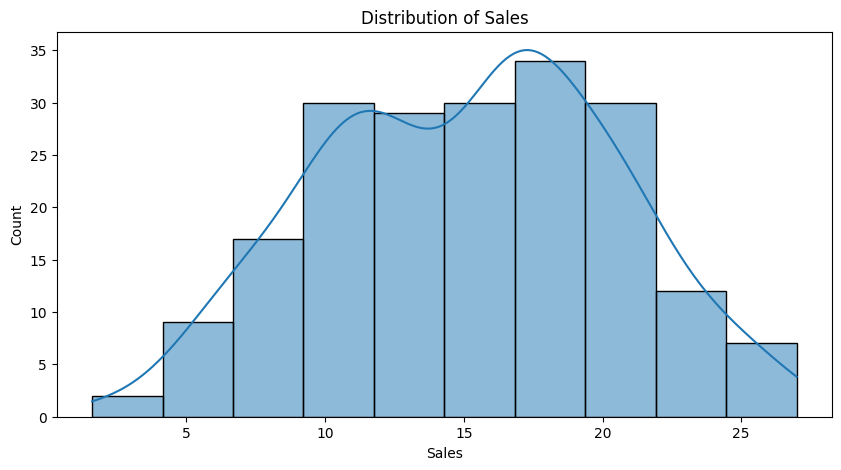

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data['Sales'], kde=True)
plt.xlabel('Sales')
plt.ylabel('Count')
plt.title('Distribution of Sales')
plt.show()


**Histogram Visualization with Subplots**

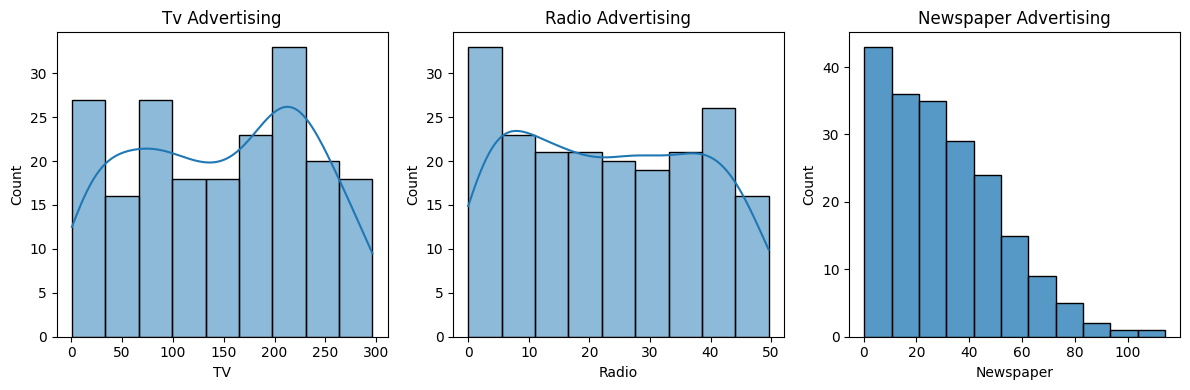

In [ ]:
# Distribution of every advertising channel
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
sns.histplot(data['TV'], kde=True)
plt.title('Tv Advertising')

plt.subplot(1, 3, 2)
sns.histplot(data['Radio'], kde=True)
plt.title('Radio Advertising')

plt.subplot(1, 3, 3)
sns.histplot(data['Newspaper'])
plt.title('Newspaper Advertising')

plt.tight_layout()
plt.show()

**Box plot Visulization**

`A Box plot summarizes data using Minimum, Q1, median, Q3, and Maximum.`

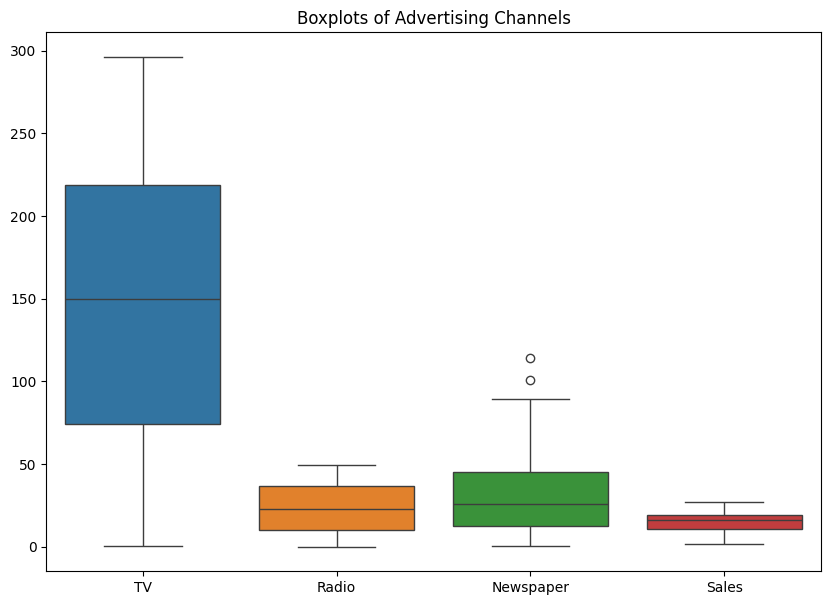

In [ ]:
plt.figure(figsize=(10, 7))
sns.boxplot(data=data)
plt.title('Boxplots of Advertising Channels')
plt.show()

**Scatter Plot Visualization with Subplots**

`A Scatter plot displays relationship between two numerical features using data points.`

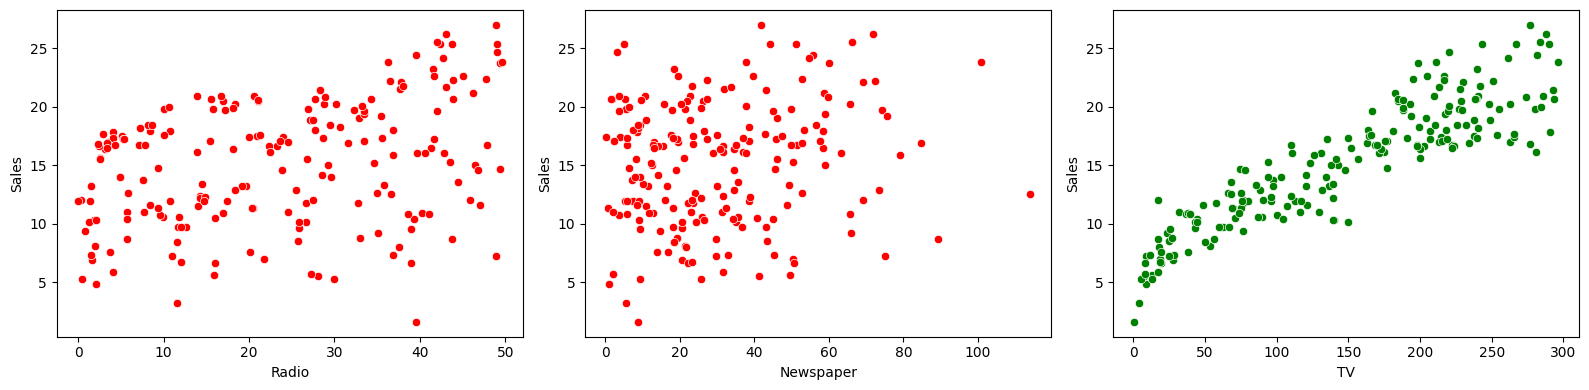

In [ ]:
plt.figure(figsize=(16,4))

plt.subplot(1, 3, 1)
sns.scatterplot(
    x=data['Radio'],
    y=data['Sales'],
    color='red'
)

plt.subplot(1, 3, 2)
sns.scatterplot(
    x=data['Newspaper'],
    y=data['Sales'],
    color='red'
)

plt.subplot(1, 3, 3)
sns.scatterplot(
    x=data['TV'],
    y=data['Sales'],
    color='green'
    )

plt.tight_layout()
plt.show()

From the above Scatter Plots you can visualize **TV advertising** has a strong **positive linear relationship** with **Sales** (Green Data points are closely aligned around a single straight regression line)

**Regression Plot Visualization**

`Scatter plot with fitted straight regression line helping identify trends.`

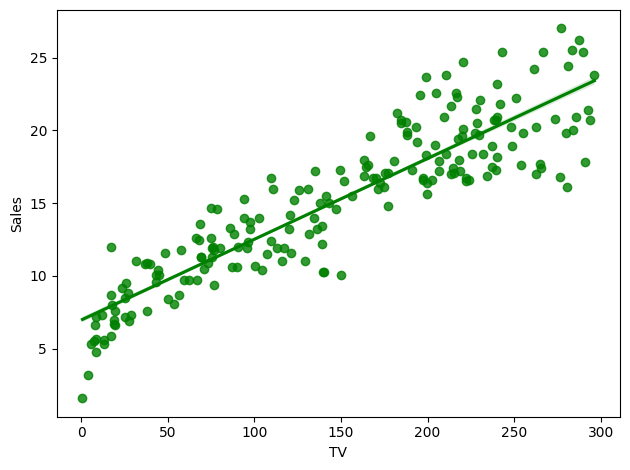

In [ ]:
# Regression Plot for 'TV advertising' column
sns.regplot(
    data=data,
    x='TV',
    y='Sales',
    color='green',
    ci=50    # Sets the confidence interval around the regression line
    )

plt.tight_layout()
plt.show()

**Regression Plot with Subplots Visualization**

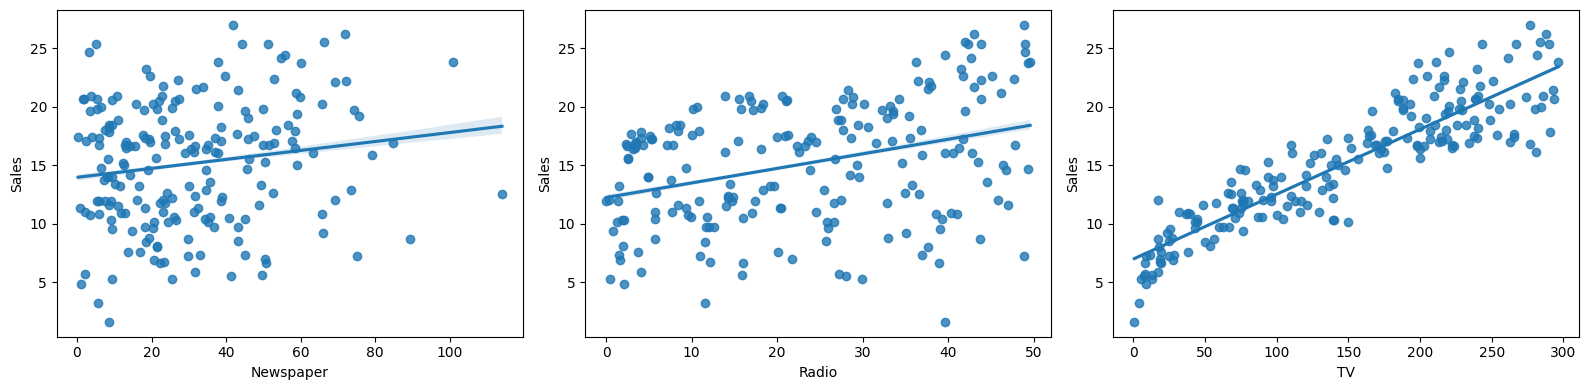

In [ ]:
plt.figure(figsize=(16,4))

plt.subplot(1, 3, 1)
sns.regplot(
            data=data,
            x='Newspaper',
            y='Sales',
            ci=35)

plt.subplot(1, 3, 2)
sns.regplot(
    data=data,
    x='Radio',
    y='Sales',
    ci=35
)

plt.subplot(1, 3, 3)
sns.regplot(
    data=data,
    x='TV',
    y='Sales',
    ci=35
)

plt.tight_layout()
plt.show()

**Correlation Matrix Using Heatmap Visualization**

`A Correlation Heatmap represents the strength and direction of relationships between numerical features using colors.`

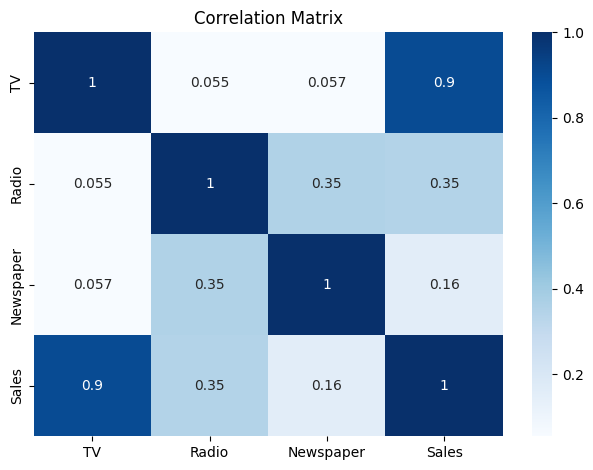

In [ ]:
correlation = data.corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap='Blues'
)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [91]:
correlation['Sales'].sort_values(ascending=False)

,Sales
Sales,1.000000
TV,0.901208
Radio,0.349631
Newspaper,0.157960


TV advertising has the strongest positive relationship with sales, followed by Radio, while Newspaper shows a comparatively weaker relationship.

**Pairplot Visualization**

`A Pair plot shows scatter plots between multiple numerical features and thier individual distributions, helping identify patterns and relationships.`

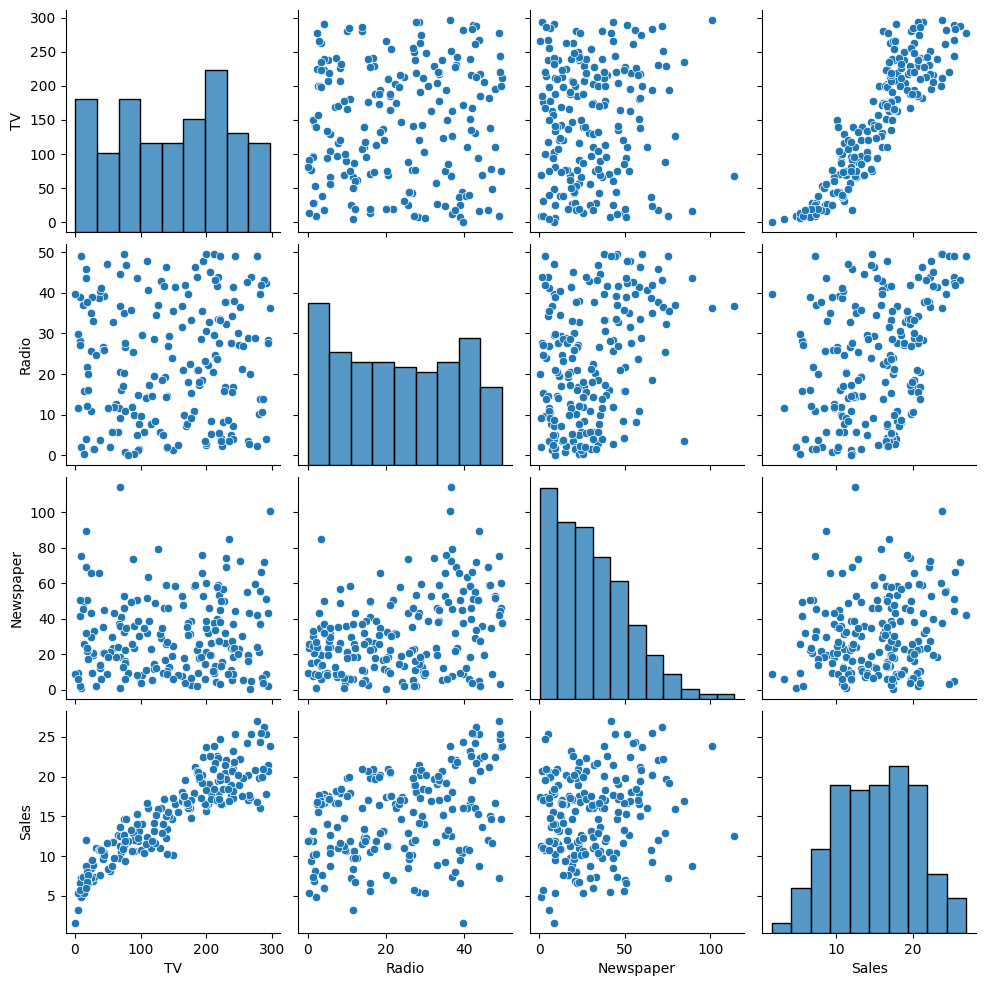

In [ ]:
sns.pairplot(data)

**Violin Plot Visualization**

`Violin Plot combines a box plot with a density plot that Shows the distribution and density of numerical data.`

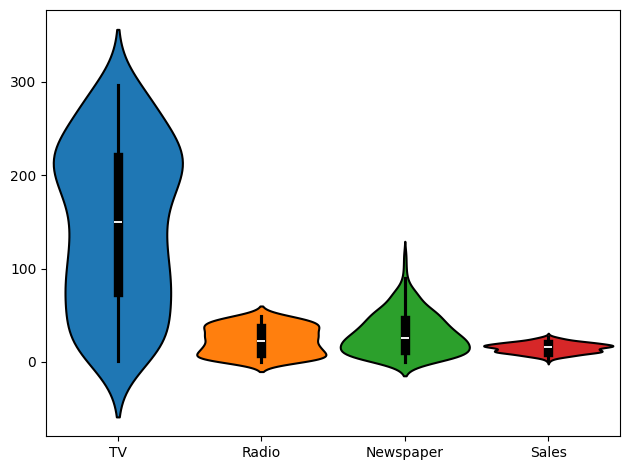

In [ ]:
sns.violinplot(
    data,
    width=0.9,
    linecolor='black',
    linewidth=1.5,
    saturation=5
    )

plt.tight_layout()
plt.show()

**Joint Plot Visualization**

`A Joint plot displays the relationship between two features along with their individual distributions (Using scatter plots and histograms). `

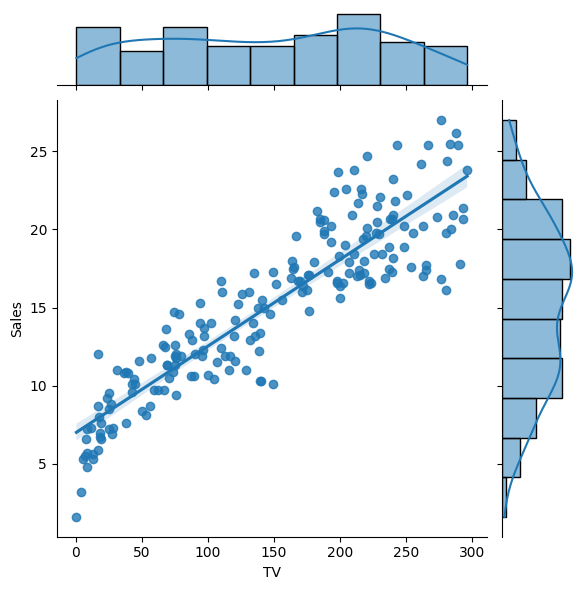

In [ ]:
sns.jointplot(data=data,
              x='TV',
              y='Sales',
              kind='reg'
              )
plt.show()


## **Model Training & Building**

In [ ]:
# Preparig Data for training
x = data[['Newspaper','Radio', 'TV']]   # Independent Variables
y = data['Sales']    # Dependent Variable (Target)

In [ ]:
# Performing train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)
print(f'Training features: {x_train.shape[0]} / Training labels: {y_train.shape[0]}')
print(f'Testing features: {x_test.shape[0]} / Testing labels: {y_test.shape[0]}')

Training features: 160 / Training labels: 160
Testing features: 40 / Testing labels: 40


In [ ]:
# Model Building
model = LinearRegression()
model.fit(x_train, y_train)   # Applying LinearRegression on Training data

LinearRegression()

In [ ]:
y_pred = model.predict(x_test)  # Model predicting on Unseen testing data
print(y_pred[:10])     # Displaying predictions

[17.0347724  20.40974033 23.72398873  9.27278518 21.68271879 12.56940161
 21.08119452  8.69035045 17.23701254 16.66657475]


In [ ]:
comparison = pd.DataFrame({
    'Actual Sales':y_test.values,
    'Predicted Sales':y_pred
})
comparison.head()

,Actual Sales,Predicted Sales
0,16.9,17.034772
1,22.4,20.409740
2,21.4,23.723989
3,7.3,9.272785
4,24.7,21.682719


## **Model Evaluation**

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)


print('MAE:',mae)
print('MSE:',mse)
print('RMSE:', rmse)
print('R2 Score:',r2)

MAE: 1.274826210954934
MSE: 2.90775691027109
RMSE: 1.7052146229349225
R2 Score: 0.9059011844150826


| Metric | Full Form | Simple Meaning | Better Value |
|---|---|---|---|
| **MAE** | Mean Absolute Error | Average of how wrong the predictions are | **Lower** |
| **MSE** | Mean Squared Error | Average of squared prediction errors; gives more importance to big errors | **Lower** |
| **RMSE** | Root Mean Squared Error | Similar to MSE, but the error is in the original units, making it easier to understand | **Lower** |
| **R² Score** | R-Squared | Shows how well the model explains/predicts the data | **Closer to 1** |

**Actual and Predicted Viualization**

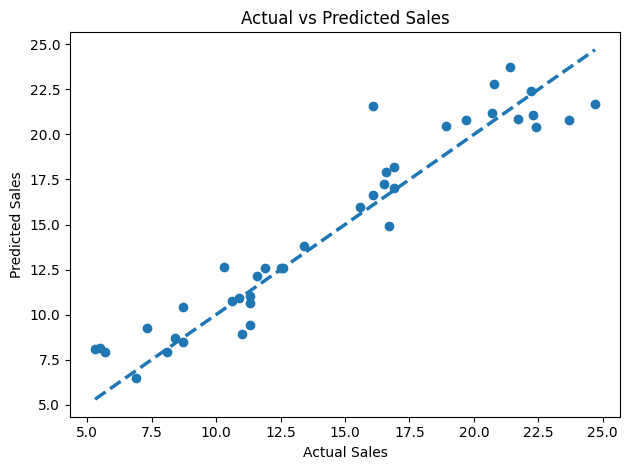

In [ ]:
plt.scatter(y_test, y_pred) # Scatter plot for two features

# Manually creating a straight line
plt.plot(
    [y_test.min(), y_test.max()],   # Joining the both min and max points using a manually created straight line
    [y_test.min(), y_test.max()],
    linestyle='--',
    linewidth=2.5
)

plt.title('Actual vs Predicted Sales')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.tight_layout()
plt.show()


### **Error Analysis**

In [ ]:
error = y_test - y_pred  # Calculating prediction errors
error_df = pd.DataFrame({
    'Actual Sales':y_test.values,
    'Predicted Sales':y_pred,
    'Error':error.values,
    'Absolute Error':np.abs(error.values)  # Non-negative errors
})
error_df.head(10)

,Actual Sales,Predicted Sales,Error,Absolute Error
0,16.9,17.034772,-0.134772,0.134772
1,22.4,20.409740,1.990260,1.990260
2,21.4,23.723989,-2.323989,2.323989
3,7.3,9.272785,-1.972785,1.972785
4,24.7,21.682719,3.017281,3.017281
5,12.6,12.569402,0.030598,0.030598
6,22.3,21.081195,1.218805,1.218805
7,8.4,8.690350,-0.290350,0.290350
8,16.5,17.237013,-0.737013,0.737013
9,16.1,16.666575,-0.566575,0.566575


## **Prediction Function**

In [81]:
def predict_sales(newspaper, radio, tv):
  input_df = pd.DataFrame({
      'Newspaper':[newspaper],
      'Radio':[radio],
      'TV':[tv]
  })
  if (not 0.7 <= tv <= 299) or (not 0 <= radio <= 50) or (not 0 <= newspaper <= 115):
    raise ValueError('Invalid input! Please enter valid numbers and try again.')
  prediction = model.predict(input_df)
  return prediction[0]

In [89]:
doc = '''These numbers are Prices measured in thousands of euros like:
0.7 ---> €700
296.4 ---> €296,400 etc... '''
print(doc)
print('=' * 60)
newspaper = float(input('Enter Newspaper Advertising spend (0 - 115): '))
radio = float(input('Enter Radio Advertising spend (0 - 50): '))
tv = float(input('Enter TV Advertising spend (0.5 - 299): '))
sales = predict_sales(newspaper, radio, tv)
print('=' * 60)
print(f'Predicted Sales: {sales:.2f} ({sales * 1000:.2f} Units)')

These numbers are Prices measured in thousands of euros like:
0.7 ---> €700
296.4 ---> €296,400 etc... 
Enter Newspaper Advertising spend (0 - 115): 114
Enter Radio Advertising spend (0 - 50): 43
Enter TV Advertising spend (0.5 - 299): 288
Predicted Sales: 25.25 (25247.82 Units)


<font color="red"><b>Re-run the above cell to enter your own inputs!!</b></font>


# **Project Summary**

This project builds a **Sales Prediction Model using Multiple Linear Regression** to estimate product sales based on advertising expenditure across three channels: TV, Radio, and Newspaper. The project includes Exploratory Data Analysis (EDA), model training, performance evaluation, error analysis, and a function for predicting sales using new advertising inputs.

## **Dataset Overview**

The dataset contains advertising expenditure and the corresponding sales figures.

- **TV:** Advertising expenditure on TV.
- **Radio:** Advertising expenditure on Radio.
- **Newspaper:** Advertising expenditure on Newspapers.
- **Sales:** Number of product units sold, represented in thousands.

**Unit interpretation:**
- Sales value of `1.6` represents approximately 1,600 units sold.
- Advertising expenditure values are measured in thousands of euros. For example, `0.7` represents €700.


## **Project Workflow**

### 1. Exploratory Data Analysis (EDA)

Several visualizations are used to understand the dataset, identify patterns, and examine relationships between advertising expenditure and sales.

- Histograms and box plots
- Scatter plots and regression plots
- Correlation matrix using a heatmap
- Pair plots, violin plots, and joint plots

These visualizations indicated that TV advertising has the strongest positive relationship with sales, followed by Radio, while Newspaper shows a comparatively weaker relationship.

### 2. Data Preparation

The independent variables are:
- Newspaper
- Radio
- TV

The target variable is **Sales**.

The dataset is split into training and testing sets using an 80/20 ratio, with `random_state=42` to ensure reproducibility.

### 3. Model Training

A **Multiple Linear Regression** model from Scikit-learn is trained using the advertising expenditure features to predict sales.

The trained model generates predictions on the unseen test dataset, which are compared with actual sales values.

### 4. Model Evaluation

The model's performance is evaluated using the following regression metrics:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted sales.
- **Mean Squared Error (MSE):** Measures the average squared prediction error.
- **Root Mean Squared Error (RMSE):** Measures prediction error in the target variable's units.
- **R² Score:** Measures how well the model explains the variation in sales.

An error analysis is also performed to examine prediction errors and absolute errors for individual test samples.

### 5. Sales Prediction System

A custom `predict_sales()` function allows users to enter advertising expenditure for Newspaper, Radio, and TV.

The function validates the input ranges and uses the trained model to predict sales. The result is displayed as both the predicted sales value in thousands of units and the corresponding estimated number of units sold.

## **Conclusion**

This project demonstrates how **Multiple Linear Regression** can be used to predict sales based on advertising expenditure across different media channels. Through data visualization, model evaluation, and error analysis, the project provides a practical introduction to regression-based machine learning and data-driven sales forecasting.
